Set up view on crop conditions, crop progress, and find the nass report data closest date to wasde report in aug

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display, clear_output


Load File Paths

In [5]:
# Project root
BASE_DIR = Path.cwd().parent

# Data files
CP_FILE = BASE_DIR / "data" / "nass" / "crop_progress.csv"


df = pd.read_csv(CP_FILE)


Crop Progress View

In [6]:
df_cp = df.copy()

#Add Week Columns

df_cp["Week Number"] = df_cp["Period"].str.extract(r"#(\d+)").astype("Int64")

df_cp["Month"] = pd.to_datetime(df["Week Ending"]).dt.month

df_cp["Category"] = (
    df_cp["Data Item"]
    .str.extract(r"MEASURED IN PCT (.+)$")[0]
    .str.strip()
)

df_cp["Type"] = (
    df_cp["Data Item"]
    .str.split(" - ", n=1)
    .str[0].str.strip()
)


test the filtered view

In [7]:
columns = [
        "Week Ending",
        "Year",
        "Month",
        "Week Number",
        "Commodity",
        "Category",
        "Type",
        "Value"
    ]

filtered = df_cp[columns]
filtered

,Week Ending,Year,Month,Week Number,Commodity,Category,Type,Value
0,2026-09-06,2027,9,36,WHEAT,PLANTED,"WHEAT, WINTER",2
1,2026-09-13,2027,9,37,WHEAT,PLANTED,"WHEAT, WINTER",8
2,2026-09-20,2027,9,38,WHEAT,EMERGED,"WHEAT, WINTER",2
3,2026-09-20,2027,9,38,WHEAT,PLANTED,"WHEAT, WINTER",17
4,2026-04-05,2026,4,14,BARLEY,PLANTED,BARLEY,5
...,...,...,...,...,...,...,...,...
4864,2009-11-22,2010,11,47,WHEAT,EMERGED,"WHEAT, WINTER",84
4865,2009-11-22,2010,11,47,WHEAT,PLANTED,"WHEAT, WINTER",93
4866,2009-11-29,2010,11,48,WHEAT,EMERGED,"WHEAT, WINTER",89
4867,2009-11-29,2010,11,48,WHEAT,PLANTED,"WHEAT, WINTER",96


In [8]:
for type_name in filtered["Type"].unique():

    type_df = filtered[filtered["Type"] == type_name]

    for category_name in type_df["Category"].unique():

        category_df = type_df[
            type_df["Category"] == category_name
        ]

        print("type:", type_name, "category:", category_name)

type: WHEAT, WINTER category: PLANTED
type: WHEAT, WINTER category: EMERGED
type: WHEAT, WINTER category: HEADED
type: WHEAT, WINTER category: HARVESTED
type: BARLEY category: PLANTED
type: BARLEY category: EMERGED
type: BARLEY category: HEADED
type: BARLEY category: HARVESTED
type: CORN category: PLANTED
type: CORN category: EMERGED
type: CORN category: SILKING
type: CORN category: DOUGH
type: CORN category: DENTED
type: CORN category: MATURE
type: SORGHUM category: PLANTED
type: SORGHUM category: HEADED
type: SORGHUM category: COLORING
type: SORGHUM category: MATURE
type: WHEAT, SPRING, (EXCL DURUM) category: PLANTED
type: WHEAT, SPRING, (EXCL DURUM) category: EMERGED
type: WHEAT, SPRING, (EXCL DURUM) category: HEADED
type: WHEAT, SPRING, (EXCL DURUM) category: HARVESTED
type: SOYBEANS category: PLANTED
type: SOYBEANS category: EMERGED
type: SOYBEANS category: BLOOMING
type: SOYBEANS category: SETTING PODS
type: SOYBEANS category: DROPPING LEAVES
type: SOYBEANS category: HARVESTED
ty

Crop Progress

In [9]:
def create_crop_view(filtered, type_name, category_name):

    view = filtered[
        (filtered["Type"] == type_name) &
        (filtered["Category"] == category_name)
    ].copy()

    view = view.sort_values("Week Number")

    return view

In [10]:
views = {}

for type_name in filtered["Type"].unique():

    type_df = filtered[
        filtered["Type"] == type_name
    ]

    for category_name in type_df["Category"].unique():

        view_name = f"{type_name}_{category_name}"
        print(view_name)
        views[view_name] = create_crop_view(
            filtered,
            type_name,
            category_name
        )


WHEAT, WINTER_PLANTED
WHEAT, WINTER_EMERGED
WHEAT, WINTER_HEADED
WHEAT, WINTER_HARVESTED
BARLEY_PLANTED
BARLEY_EMERGED
BARLEY_HEADED
BARLEY_HARVESTED
CORN_PLANTED
CORN_EMERGED
CORN_SILKING
CORN_DOUGH
CORN_DENTED
CORN_MATURE
SORGHUM_PLANTED
SORGHUM_HEADED
SORGHUM_COLORING
SORGHUM_MATURE
WHEAT, SPRING, (EXCL DURUM)_PLANTED
WHEAT, SPRING, (EXCL DURUM)_EMERGED
WHEAT, SPRING, (EXCL DURUM)_HEADED
WHEAT, SPRING, (EXCL DURUM)_HARVESTED
SOYBEANS_PLANTED
SOYBEANS_EMERGED
SOYBEANS_BLOOMING
SOYBEANS_SETTING PODS
SOYBEANS_DROPPING LEAVES
SOYBEANS_HARVESTED
SORGHUM, GRAIN_HARVESTED
CORN, GRAIN_HARVESTED


In [11]:
#filter function

def get_crop_view(filtered, type_name, category_name):

    return (
        filtered[
            (filtered["Type"] == type_name) &
            (filtered["Category"] == category_name)
        ]
        .sort_values(["Year", "Week Number"])
        .copy()
    )

In [12]:
current_year = filtered["Year"].max()

historical = filtered[
    filtered["Year"].between(
        current_year - 5,
        current_year - 1
    )
]

five_year_stats = (
    historical
    .groupby(["Type", "Category", "Week Number"])["Value"]
    .agg(
        **{
            "5Y Average": "mean",
            "5Y Min": "min",
            "5Y Max": "max"
        }
    )
    .reset_index()
)

filtered = filtered.merge(
    five_year_stats,
    on=["Type", "Category", "Week Number"],
    how="left"
)

In [13]:


def plot_crop_progress_seasonality(
    filtered,
    type_name,
    category_name,
    current_year=None
):
    # Determine current year
    if current_year is None:
        current_year = filtered["Year"].max()

    # Filter selected crop and category
    crop = filtered[
        (filtered["Type"] == type_name) &
        (filtered["Category"] == category_name)
    ].copy()

    # Separate historical years from current year
    historical = crop[
        crop["Year"].between(
            current_year - 5,
            current_year - 1
        )
    ].copy()

    current = crop[
        crop["Year"] == current_year
    ].copy()

    # Calculate historical weekly minimum and maximum
    stats = (
        historical
        .groupby("Week Number")["Value"]
        .agg(
            Minimum="min",
            Maximum="max"
        )
        .reset_index()
        .sort_values("Week Number")
    )

    # Current year's weekly observations
    current = (
        current[["Week Number", "Value"]]
        .rename(columns={"Value": str(current_year)})
        .sort_values("Week Number")
    )

    # Create chart
    fig = go.Figure()

    # Historical maximum: upper boundary
    fig.add_trace(
        go.Scatter(
            x=stats["Week Number"],
            y=stats["Maximum"],
            mode="lines",
            line=dict(width=0),
            showlegend=False,
            hoverinfo="skip"
        )
    )

    # Historical minimum: lower boundary + shaded range
    fig.add_trace(
        go.Scatter(
            x=stats["Week Number"],
            y=stats["Minimum"],
            mode="lines",
            line=dict(width=0),
            fill="tonexty",
            fillcolor="rgba(100, 149, 237, 0.20)",
            name="Previous 5 Years Range",
            hovertemplate=(
                "Week %{x}<br>"
                "Historical Minimum: %{y:.1f}%"
                "<extra></extra>"
            )
        )
    )

    # Current year
    fig.add_trace(
        go.Scatter(
            x=current["Week Number"],
            y=current[str(current_year)],
            mode="lines+markers",
            name=str(current_year),
            line=dict(color="#d62728", width=3),
            marker=dict(size=5),
            hovertemplate=(
                "Week %{x}<br>"
                f"{current_year}: "
                "%{{y:.1f}}%<extra></extra>"
            )
        )
    )

    # USDA-style presentation
    fig.update_layout(
        title=f"{type_name} – {category_name} Progress",
        template="plotly_white",
        height=600,
        hovermode="x unified",
        xaxis_title="Week Number",
        yaxis_title="Crop Progress (%)",
        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="left",
            x=0
        ),
        margin=dict(l=60, r=30, t=100, b=60)
    )

    fig.update_xaxes(
        dtick=2,
        showgrid=False,
        zeroline=False
    )

    fig.update_yaxes(
        ticksuffix="%",
        rangemode="tozero",
        showgrid=True,
        gridcolor="rgba(128, 128, 128, 0.2)"
    )

    return fig

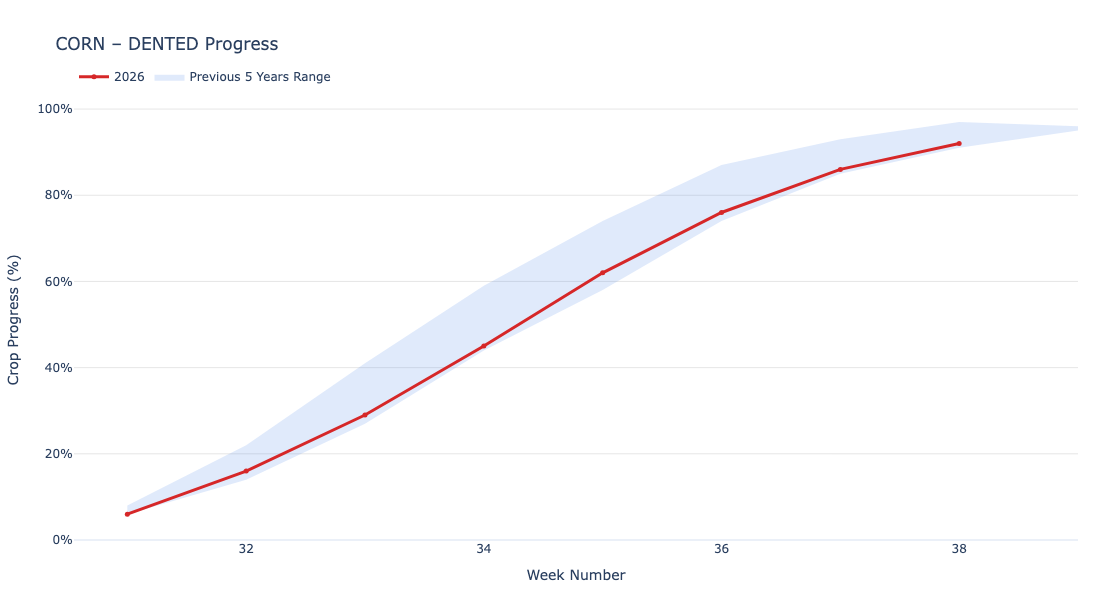

In [14]:
fig = plot_crop_progress_seasonality(
    filtered,
    type_name="CORN",
    category_name="DENTED",
    current_year = 2026
    
)

fig.show()

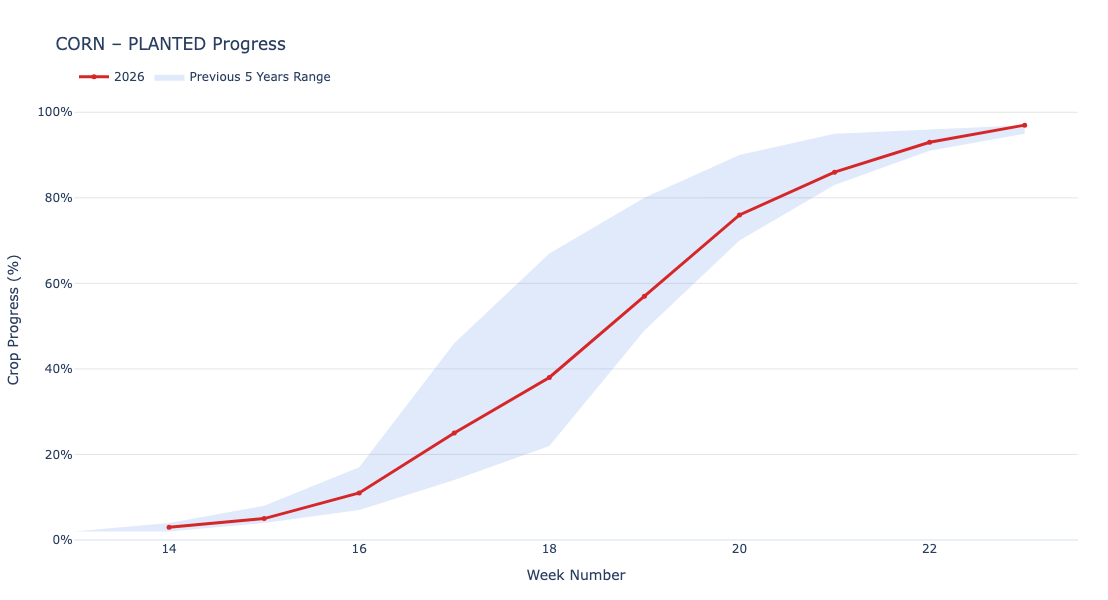

In [15]:
fig = plot_crop_progress_seasonality(
    filtered,
    type_name="CORN",
    category_name="PLANTED",
    current_year = 2026
)

fig.show()

In [16]:
print(filtered["Year"].unique())
print("Current year:", filtered["Year"].max())

[2027 2026 2025 2024 2023 2022 2021 2020 2019 2018 2017 2016 2015 2014
 2013 2012 2011 2010]
Current year: 2027


In [19]:
from datetime import datetime

import pandas as pd
import plotly.graph_objects as go
import ipywidgets as widgets

from IPython.display import display


# ============================================================
# PREPARE DATA ONCE
# ============================================================

filtered = filtered.copy()

filtered["Year"] = pd.to_numeric(
    filtered["Year"],
    errors="coerce"
)

filtered["Week Number"] = pd.to_numeric(
    filtered["Week Number"],
    errors="coerce"
)

filtered["Value"] = pd.to_numeric(
    filtered["Value"],
    errors="coerce"
)


# ============================================================
# 1. SINGLE CATEGORY CHART
# ============================================================

def plot_crop_progress_seasonality(
    filtered,
    type_name,
    category_name,
    current_year=None
):

    # --------------------------------------------------------
    # Determine current year
    # --------------------------------------------------------

    if current_year is None:
        current_year = datetime.now().year

    previous_year = current_year - 1


    # --------------------------------------------------------
    # Filter selected Type + Category
    # --------------------------------------------------------

    crop = filtered[
        (filtered["Type"] == type_name) &
        (filtered["Category"] == category_name)
    ].copy()


    if crop.empty:
        return None


    # --------------------------------------------------------
    # Previous 5 years
    #
    # Example for 2026:
    # 2021, 2022, 2023, 2024, 2025
    # --------------------------------------------------------

    historical = crop[
        crop["Year"].between(
            current_year - 5,
            previous_year
        )
    ].copy()


    # --------------------------------------------------------
    # Previous year
    # --------------------------------------------------------

    previous = crop[
        crop["Year"] == previous_year
    ].copy()


    # --------------------------------------------------------
    # Current year
    # --------------------------------------------------------

    current = crop[
        crop["Year"] == current_year
    ].copy()


    # --------------------------------------------------------
    # Historical weekly minimum / maximum
    # --------------------------------------------------------

    stats = (
        historical
        .dropna(
            subset=[
                "Week Number",
                "Value"
            ]
        )
        .groupby("Week Number")["Value"]
        .agg(
            Minimum="min",
            Maximum="max"
        )
        .reset_index()
        .sort_values("Week Number")
    )


    # ========================================================
    # CREATE FIGURE
    # ========================================================

    fig = go.Figure()


    # ========================================================
    # HISTORICAL 5-YEAR RANGE
    # ========================================================

    if not stats.empty:

        # ----------------------------------------------------
        # Historical maximum
        # ----------------------------------------------------

        fig.add_trace(
            go.Scatter(
                x=stats["Week Number"],
                y=stats["Maximum"],
                mode="lines",
                line=dict(width=0),
                showlegend=False,
                hoverinfo="skip"
            )
        )


        # ----------------------------------------------------
        # Historical minimum + shaded range
        # ----------------------------------------------------

        fig.add_trace(
            go.Scatter(
                x=stats["Week Number"],
                y=stats["Minimum"],
                mode="lines",
                line=dict(width=0),
                fill="tonexty",
                fillcolor="rgba(100, 149, 237, 0.20)",
                name="Previous 5 Years Range",
                hovertemplate=(
                    "Week %{x}<br>"
                    "Historical Minimum: %{y:.1f}%"
                    "<extra></extra>"
                )
            )
        )


    # ========================================================
    # PREVIOUS YEAR
    # ========================================================

    previous = (
        previous[
            [
                "Week Number",
                "Value"
            ]
        ]
        .dropna()
        .sort_values("Week Number")
    )


    if not previous.empty:

        fig.add_trace(
            go.Scatter(
                x=previous["Week Number"],
                y=previous["Value"],
                mode="lines+markers",
                name=str(previous_year),
                line=dict(
                    width=2
                ),
                marker=dict(
                    size=4
                ),
                hovertemplate=(
                    "Week %{x}<br>"
                    f"{previous_year}: "
                    "%{y:.1f}%"
                    "<extra></extra>"
                )
            )
        )


    # ========================================================
    # CURRENT YEAR
    # ========================================================

    current = (
        current[
            [
                "Week Number",
                "Value"
            ]
        ]
        .dropna()
        .sort_values("Week Number")
    )


    if not current.empty:

        fig.add_trace(
            go.Scatter(
                x=current["Week Number"],
                y=current["Value"],
                mode="lines+markers",
                name=str(current_year),
                line=dict(
                    color="#d62728",
                    width=3
                ),
                marker=dict(
                    size=5
                ),
                hovertemplate=(
                    "Week %{x}<br>"
                    f"{current_year}: "
                    "%{y:.1f}%"
                    "<extra></extra>"
                )
            )
        )


    # ========================================================
    # LAYOUT
    # ========================================================

    fig.update_layout(
        title=(
            f"{type_name} – "
            f"{category_name} Progress"
        ),

        template="plotly_white",

        height=500,

        hovermode="x unified",

        xaxis_title="Week Number",

        yaxis_title="Crop Progress (%)",

        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="left",
            x=0
        ),

        margin=dict(
            l=60,
            r=30,
            t=100,
            b=60
        )
    )


    # ========================================================
    # X AXIS
    # ========================================================

    fig.update_xaxes(
        dtick=2,
        showgrid=False,
        zeroline=False
    )


    # ========================================================
    # Y AXIS
    # ========================================================

    fig.update_yaxes(
        ticksuffix="%",
        rangemode="tozero",
        showgrid=True,
        gridcolor="rgba(128, 128, 128, 0.2)"
    )


    return fig


# ============================================================
# 2. PLOT ALL CATEGORIES FOR SELECTED TYPE
# ============================================================

def plot_all_crop_progress_categories(
    filtered,
    type_name,
    current_year=None
):

    # --------------------------------------------------------
    # Determine current year
    # --------------------------------------------------------

    if current_year is None:
        current_year = datetime.now().year


    # --------------------------------------------------------
    # Get categories belonging to selected Type
    # --------------------------------------------------------

    categories = sorted(
        filtered.loc[
            filtered["Type"] == type_name,
            "Category"
        ]
        .dropna()
        .unique()
    )


    # --------------------------------------------------------
    # Plot every category
    # --------------------------------------------------------

    for category_name in categories:

        fig = plot_crop_progress_seasonality(
            filtered=filtered,
            type_name=type_name,
            category_name=category_name,
            current_year=current_year
        )

        if fig is not None:
            fig.show()


# ============================================================
# 3. TYPE DROPDOWN
# ============================================================

type_options = sorted(
    filtered["Type"]
    .dropna()
    .unique()
)


type_dropdown = widgets.Dropdown(
    options=type_options,
    description="Type:",
    value=(
        type_options[0]
        if type_options
        else None
    ),
    layout=widgets.Layout(
        width="300px"
    )
)


# ============================================================
# 4. DEDICATED CHART OUTPUT AREA
# ============================================================

chart_output = widgets.Output()


# ============================================================
# 5. UPDATE CHARTS WHEN TYPE CHANGES
# ============================================================

def update_charts(change):

    if change["name"] != "value":
        return


    with chart_output:

        # Remove previous charts
        chart_output.clear_output(
            wait=True
        )


        # Draw charts for newly selected Type
        plot_all_crop_progress_categories(
            filtered=filtered,
            type_name=change["new"]
        )


# ============================================================
# 6. CONNECT DROPDOWN
# ============================================================

type_dropdown.observe(
    update_charts,
    names="value"
)


# ============================================================
# 7. INITIAL CHARTS
# ============================================================

with chart_output:

    plot_all_crop_progress_categories(
        filtered=filtered,
        type_name=type_dropdown.value
    )


# ============================================================
# 8. DISPLAY DROPDOWN + CHARTS
# ============================================================

display(
    type_dropdown,
    chart_output
)

Dropdown(description='Type:', layout=Layout(width='300px'), options=('BARLEY', 'CORN', 'CORN, GRAIN', 'SORGHUM…

Output()

In [20]:
from datetime import datetime

import pandas as pd
import plotly.graph_objects as go
import ipywidgets as widgets

from IPython.display import display


# ============================================================
# PREPARE DATA ONCE
# ============================================================

filtered = filtered.copy()

filtered["Year"] = pd.to_numeric(
    filtered["Year"],
    errors="coerce"
)

filtered["Week Number"] = pd.to_numeric(
    filtered["Week Number"],
    errors="coerce"
)

filtered["Value"] = pd.to_numeric(
    filtered["Value"],
    errors="coerce"
)


# ============================================================
# 1. PLOT ONE CHART FOR ONE TYPE
# ============================================================

def plot_crop_progress(
    filtered,
    type_name,
    current_year=None
):

    # --------------------------------------------------------
    # Determine current and previous year
    # --------------------------------------------------------

    if current_year is None:
        current_year = datetime.now().year

    previous_year = current_year - 1


    # --------------------------------------------------------
    # Filter selected Type
    # --------------------------------------------------------

    crop = filtered[
        filtered["Type"] == type_name
    ].copy()


    if crop.empty:
        return None


    # --------------------------------------------------------
    # Get categories belonging to selected Type
    # --------------------------------------------------------

    categories = sorted(
        crop["Category"]
        .dropna()
        .unique()
    )


    if not categories:
        return None


    # ========================================================
    # CREATE FIGURE
    # ========================================================

    fig = go.Figure()


    # ========================================================
    # LOOP THROUGH CATEGORIES
    # ========================================================

    for category_name in categories:

        # ----------------------------------------------------
        # Filter category
        # ----------------------------------------------------

        category = crop[
            crop["Category"] == category_name
        ].copy()


        # ----------------------------------------------------
        # Previous 5 years
        #
        # For 2026:
        # 2021, 2022, 2023, 2024, 2025
        # ----------------------------------------------------

        historical = category[
            category["Year"].between(
                current_year - 5,
                previous_year
            )
        ].copy()


        # ----------------------------------------------------
        # Previous year
        # ----------------------------------------------------

        previous = category[
            category["Year"] == previous_year
        ].copy()


        # ----------------------------------------------------
        # Current year
        # ----------------------------------------------------

        current = category[
            category["Year"] == current_year
        ].copy()


        # ====================================================
        # HISTORICAL 5-YEAR RANGE
        # ====================================================

        stats = (
            historical
            .dropna(
                subset=[
                    "Week Number",
                    "Value"
                ]
            )
            .groupby("Week Number")["Value"]
            .agg(
                Minimum="min",
                Maximum="max"
            )
            .reset_index()
            .sort_values("Week Number")
        )


        if not stats.empty:

            # ------------------------------------------------
            # Historical maximum
            # ------------------------------------------------

            fig.add_trace(
                go.Scatter(
                    x=stats["Week Number"],
                    y=stats["Maximum"],
                    mode="lines",
                    line=dict(
                        width=0
                    ),
                    showlegend=False,
                    hoverinfo="skip"
                )
            )


            # ------------------------------------------------
            # Historical minimum
            # + shaded range
            # ------------------------------------------------

            fig.add_trace(
                go.Scatter(
                    x=stats["Week Number"],
                    y=stats["Minimum"],
                    mode="lines",
                    line=dict(
                        width=0
                    ),
                    fill="tonexty",
                    fillcolor="rgba(100, 149, 237, 0.12)",
                    name=f"{category_name} – 5Y Range",
                    hovertemplate=(
                        f"{category_name}<br>"
                        "Week %{x}<br>"
                        "Historical Minimum: %{y:.1f}%"
                        "<extra></extra>"
                    )
                )
            )


        # ====================================================
        # PREVIOUS YEAR
        # ====================================================

        previous = (
            previous[
                [
                    "Week Number",
                    "Value"
                ]
            ]
            .dropna()
            .sort_values("Week Number")
        )


        if not previous.empty:

            fig.add_trace(
                go.Scatter(
                    x=previous["Week Number"],
                    y=previous["Value"],
                    mode="lines+markers",
                    name=f"{category_name} {previous_year}",
                    line=dict(
                        width=2
                    ),
                    marker=dict(
                        size=4
                    ),
                    hovertemplate=(
                        f"{category_name}<br>"
                        "Week %{x}<br>"
                        f"{previous_year}: "
                        "%{y:.1f}%"
                        "<extra></extra>"
                    )
                )
            )


        # ====================================================
        # CURRENT YEAR
        # ====================================================

        current = (
            current[
                [
                    "Week Number",
                    "Value"
                ]
            ]
            .dropna()
            .sort_values("Week Number")
        )


        if not current.empty:

            fig.add_trace(
                go.Scatter(
                    x=current["Week Number"],
                    y=current["Value"],
                    mode="lines+markers",
                    name=f"{category_name} {current_year}",
                    line=dict(
                        width=3
                    ),
                    marker=dict(
                        size=5
                    ),
                    hovertemplate=(
                        f"{category_name}<br>"
                        "Week %{x}<br>"
                        f"{current_year}: "
                        "%{y:.1f}%"
                        "<extra></extra>"
                    )
                )
            )


    # ========================================================
    # LAYOUT
    # ========================================================

    fig.update_layout(

        title=(
            f"{type_name} Crop Progress "
            f"– {current_year} vs {previous_year}"
        ),

        template="plotly_white",

        height=650,

        hovermode="x unified",

        xaxis_title="Week Number",

        yaxis_title="Crop Progress (%)",

        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="left",
            x=0
        ),

        margin=dict(
            l=60,
            r=30,
            t=120,
            b=60
        )
    )


    # ========================================================
    # X AXIS
    # ========================================================

    fig.update_xaxes(
        range=[1, 52],
        dtick=2,
        showgrid=False,
        zeroline=False
    )


    # ========================================================
    # Y AXIS
    # ========================================================

    fig.update_yaxes(
        range=[0, 100],
        ticksuffix="%",
        showgrid=True,
        gridcolor="rgba(128, 128, 128, 0.2)"
    )


    return fig


# ============================================================
# 2. TYPE DROPDOWN
# ============================================================

type_options = sorted(
    filtered["Type"]
    .dropna()
    .unique()
)


type_dropdown = widgets.Dropdown(
    options=type_options,
    description="Type:",
    value=(
        type_options[0]
        if type_options
        else None
    ),
    layout=widgets.Layout(
        width="300px"
    )
)


# ============================================================
# 3. CHART OUTPUT AREA
# ============================================================

chart_output = widgets.Output()


# ============================================================
# 4. UPDATE CHART WHEN TYPE CHANGES
# ============================================================

def update_chart(change):

    if change["name"] != "value":
        return

    with chart_output:

        chart_output.clear_output(
            wait=True
        )

        fig = plot_crop_progress(
            filtered=filtered,
            type_name=change["new"]
        )

        if fig is not None:
            fig.show()


# ============================================================
# 5. CONNECT DROPDOWN
# ============================================================

type_dropdown.observe(
    update_chart,
    names="value"
)


# ============================================================
# 6. INITIAL CHART
# ============================================================

with chart_output:

    fig = plot_crop_progress(
        filtered=filtered,
        type_name=type_dropdown.value
    )

    if fig is not None:
        fig.show()


# ============================================================
# 7. DISPLAY
# ============================================================

display(
    type_dropdown,
    chart_output
)

Dropdown(description='Type:', layout=Layout(width='300px'), options=('BARLEY', 'CORN', 'CORN, GRAIN', 'SORGHUM…

Output()

In [21]:
from datetime import datetime

import pandas as pd
import plotly.graph_objects as go
import ipywidgets as widgets

from IPython.display import display


# ============================================================
# PREPARE DATA ONCE
# ============================================================

filtered = filtered.copy()

filtered["Year"] = pd.to_numeric(
    filtered["Year"],
    errors="coerce"
)

filtered["Week Number"] = pd.to_numeric(
    filtered["Week Number"],
    errors="coerce"
)

filtered["Value"] = pd.to_numeric(
    filtered["Value"],
    errors="coerce"
)


# ============================================================
# COLOUR PALETTE
# ============================================================

# Each crop stage gets one base colour.
# The year is represented by shade:
#
# 5Y Historical = dotted, medium-light
# Previous year = light
# Current year  = dark
#
# Additional categories automatically receive another colour.

BASE_COLORS = [
    "#1f77b4",   # blue
    "#2ca02c",   # green
    "#ff7f0e",   # orange
    "#9467bd",   # purple
    "#17becf",   # cyan
    "#d62728",   # red
    "#8c564b",   # brown
    "#e377c2",   # pink
    "#bcbd22",   # olive
    "#7f7f7f"    # grey
]


# ============================================================
# HELPER: LIGHTEN COLOUR
# ============================================================

def lighten_color(
    hex_color,
    amount
):

    hex_color = hex_color.lstrip("#")

    red = int(
        hex_color[0:2],
        16
    )

    green = int(
        hex_color[2:4],
        16
    )

    blue = int(
        hex_color[4:6],
        16
    )


    red = round(
        red + (255 - red) * amount
    )

    green = round(
        green + (255 - green) * amount
    )

    blue = round(
        blue + (255 - blue) * amount
    )


    return (
        f"#{red:02x}"
        f"{green:02x}"
        f"{blue:02x}"
    )


# ============================================================
# 1. PLOT ONE CHART FOR ONE TYPE
# ============================================================

def plot_crop_progress(
    filtered,
    type_name,
    current_year=None
):

    # --------------------------------------------------------
    # Determine years
    # --------------------------------------------------------

    if current_year is None:
        current_year = datetime.now().year

    previous_year = current_year - 1


    # --------------------------------------------------------
    # Filter selected Type
    # --------------------------------------------------------

    crop = filtered[
        filtered["Type"] == type_name
    ].copy()


    if crop.empty:
        return None


    # --------------------------------------------------------
    # Get categories
    # --------------------------------------------------------

    categories = sorted(
        crop["Category"]
        .dropna()
        .unique()
    )


    if not categories:
        return None


    # ========================================================
    # CREATE FIGURE
    # ========================================================

    fig = go.Figure()


    # ========================================================
    # LOOP THROUGH CATEGORIES
    # ========================================================

    for category_index, category_name in enumerate(categories):

        # ----------------------------------------------------
        # Assign base colour to category
        # ----------------------------------------------------

        base_color = BASE_COLORS[
            category_index % len(BASE_COLORS)
        ]


        # ----------------------------------------------------
        # Create lighter shades
        # ----------------------------------------------------

        historical_color = lighten_color(
            base_color,
            0.55
        )

        previous_color = lighten_color(
            base_color,
            0.35
        )

        current_color = base_color


        # ----------------------------------------------------
        # Filter category
        # ----------------------------------------------------

        category = crop[
            crop["Category"] == category_name
        ].copy()


        # ----------------------------------------------------
        # Previous 5 years
        #
        # Example for 2026:
        # 2021–2025
        # ----------------------------------------------------

        historical = category[
            category["Year"].between(
                current_year - 5,
                previous_year
            )
        ].copy()


        # ----------------------------------------------------
        # Previous year
        # ----------------------------------------------------

        previous = category[
            category["Year"] == previous_year
        ].copy()


        # ----------------------------------------------------
        # Current year
        # ----------------------------------------------------

        current = category[
            category["Year"] == current_year
        ].copy()


        # ====================================================
        # 5-YEAR HISTORICAL AVERAGE
        # ====================================================

        historical_stats = (
            historical
            .dropna(
                subset=[
                    "Week Number",
                    "Value"
                ]
            )
            .groupby("Week Number")["Value"]
            .mean()
            .reset_index(
                name="Value"
            )
            .sort_values("Week Number")
        )


        if not historical_stats.empty:

            fig.add_trace(
                go.Scatter(
                    x=historical_stats["Week Number"],
                    y=historical_stats["Value"],
                    mode="lines",
                    name=(
                        f"{category_name} "
                        f"5Y Avg"
                    ),
                    line=dict(
                        color=historical_color,
                        width=2,
                        dash="dot"
                    ),
                    hovertemplate=(
                        f"{category_name}<br>"
                        "Week %{x}<br>"
                        "5Y Average: "
                        "%{y:.1f}%"
                        "<extra></extra>"
                    )
                )
            )


        # ====================================================
        # PREVIOUS YEAR
        # ====================================================

        previous = (
            previous[
                [
                    "Week Number",
                    "Value"
                ]
            ]
            .dropna()
            .sort_values("Week Number")
        )


        if not previous.empty:

            fig.add_trace(
                go.Scatter(
                    x=previous["Week Number"],
                    y=previous["Value"],
                    mode="lines+markers",
                    name=(
                        f"{category_name} "
                        f"{previous_year}"
                    ),
                    line=dict(
                        color=previous_color,
                        width=2
                    ),
                    marker=dict(
                        color=previous_color,
                        size=4
                    ),
                    hovertemplate=(
                        f"{category_name}<br>"
                        "Week %{x}<br>"
                        f"{previous_year}: "
                        "%{y:.1f}%"
                        "<extra></extra>"
                    )
                )
            )


        # ====================================================
        # CURRENT YEAR
        # ====================================================

        current = (
            current[
                [
                    "Week Number",
                    "Value"
                ]
            ]
            .dropna()
            .sort_values("Week Number")
        )


        if not current.empty:

            fig.add_trace(
                go.Scatter(
                    x=current["Week Number"],
                    y=current["Value"],
                    mode="lines+markers",
                    name=(
                        f"{category_name} "
                        f"{current_year}"
                    ),
                    line=dict(
                        color=current_color,
                        width=3
                    ),
                    marker=dict(
                        color=current_color,
                        size=5
                    ),
                    hovertemplate=(
                        f"{category_name}<br>"
                        "Week %{x}<br>"
                        f"{current_year}: "
                        "%{y:.1f}%"
                        "<extra></extra>"
                    )
                )
            )


    # ========================================================
    # LAYOUT
    # ========================================================

    fig.update_layout(

        title=(
            f"{type_name} Crop Progress "
            f"– {current_year} vs {previous_year}"
        ),

        template="plotly_white",

        height=650,

        hovermode="x unified",

        xaxis_title="Week Number",

        yaxis_title="Crop Progress (%)",

        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="left",
            x=0
        ),

        margin=dict(
            l=60,
            r=30,
            t=120,
            b=60
        )
    )


    # ========================================================
    # X AXIS
    # ========================================================

    fig.update_xaxes(
        range=[1, 52],
        dtick=2,
        showgrid=False,
        zeroline=False
    )


    # ========================================================
    # Y AXIS
    # ========================================================

    fig.update_yaxes(
        range=[0, 100],
        ticksuffix="%",
        showgrid=True,
        gridcolor="rgba(128, 128, 128, 0.2)"
    )


    return fig


# ============================================================
# 2. TYPE DROPDOWN
# ============================================================

type_options = sorted(
    filtered["Type"]
    .dropna()
    .unique()
)


type_dropdown = widgets.Dropdown(
    options=type_options,
    description="Type:",
    value=(
        type_options[0]
        if type_options
        else None
    ),
    layout=widgets.Layout(
        width="300px"
    )
)


# ============================================================
# 3. CHART OUTPUT AREA
# ============================================================

chart_output = widgets.Output()


# ============================================================
# 4. UPDATE CHART WHEN TYPE CHANGES
# ============================================================

def update_chart(change):

    if change["name"] != "value":
        return


    with chart_output:

        chart_output.clear_output(
            wait=True
        )


        fig = plot_crop_progress(
            filtered=filtered,
            type_name=change["new"]
        )


        if fig is not None:
            fig.show()


# ============================================================
# 5. CONNECT DROPDOWN
# ============================================================

type_dropdown.observe(
    update_chart,
    names="value"
)


# ============================================================
# 6. INITIAL CHART
# ============================================================

with chart_output:

    fig = plot_crop_progress(
        filtered=filtered,
        type_name=type_dropdown.value
    )


    if fig is not None:
        fig.show()


# ============================================================
# 7. DISPLAY
# ============================================================

display(
    type_dropdown,
    chart_output
)

Dropdown(description='Type:', layout=Layout(width='300px'), options=('BARLEY', 'CORN', 'CORN, GRAIN', 'SORGHUM…

Output()